<a href="https://colab.research.google.com/github/Pedro050723/Projeto-Pratico-2.1-Pedro-Miranda/blob/main/Projeto_Pr%C3%A1tico2_1_RNA_PEDRO_HENRIQUE_MIRANDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Redes Neurais Artificiais – Projeto Prático 2.1

**Aluno:** Pedro Henrique Miranda do Valle

## Parte I – Perceptron em um problema linearmente separável

**Objetivo:** implementar o algoritmo de treinamento do neurônio Perceptron (Rosenblatt) e usá-lo para separar duas classes de pontos do arquivo `dataAll20262.txt`.

## Importando as bibliotecas utilizadas no projeto

In [179]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from prettytable import PrettyTable
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

## Os arquivos que serão utilizados

In [180]:
CAMINHO_PARTE1 = "dataAll20262.txt"
CAMINHO_PARTE2 = "data020262.txt"
CAMINHO_PARTE3 = "dataHoldout20262.txt"

In [181]:
dados = np.load(CAMINHO_PARTE1)            # lê o ndarray salvo em binário
print("Shape original:", dados.shape)

dados = dados.reshape(-1, 3)        # (m, 1, 3) -> (m, 3)
print("Shape após reshape:", dados.shape)

print("\nPrimeiras 5 linhas (x1, x2, yd):")
print(dados[:5])

Shape original: (1000, 1, 3)
Shape após reshape: (1000, 3)

Primeiras 5 linhas (x1, x2, yd):
[[ 547.91209711 -122.2431205     1.        ]
 [ 717.19583982  394.73605812    0.        ]
 [-811.64530422  951.24470327    0.        ]
 [ 522.27940398  572.12861055    0.        ]
 [-743.77273465  -99.22812421    0.        ]]


In [182]:
X_orig = dados[:, :2]          # todas as linhas, colunas 0 e 1  -> (x1, x2)
y_d    = dados[:, 2]           # todas as linhas, coluna 2        -> rótulo

m = X_orig.shape[0]            # número de exemplos
print("Número de exemplos:", m)

classes, contagens = np.unique(y_d, return_counts=True)
for c, n in zip(classes, contagens):
    print(f"Classe {int(c)}: {n} exemplos")

Número de exemplos: 1000
Classe 0: 500 exemplos
Classe 1: 500 exemplos


In [183]:
df_dados = pd.DataFrame(dados, columns=["x1", "x2", "yd"])
df_dados["yd"] = df_dados["yd"].astype(int)       # rótulo como inteiro (0 ou 1)

display(df_dados.head())
display(df_dados.describe().round(2))

,x1,x2,yd
0,547.912097,-122.243120,1
1,717.195840,394.736058,0
2,-811.645304,951.244703,0
3,522.279404,572.128611,0
4,-743.772735,-99.228124,0


,x1,x2,yd
count,1000.00,1000.00,1000.0
mean,0.47,10.88,0.5
std,590.77,571.10,0.5
min,-998.86,-998.96,0.0
25%,-526.83,-484.87,0.0
50%,-13.78,-1.02,0.5
75%,529.40,508.70,1.0
max,998.84,998.21,1.0


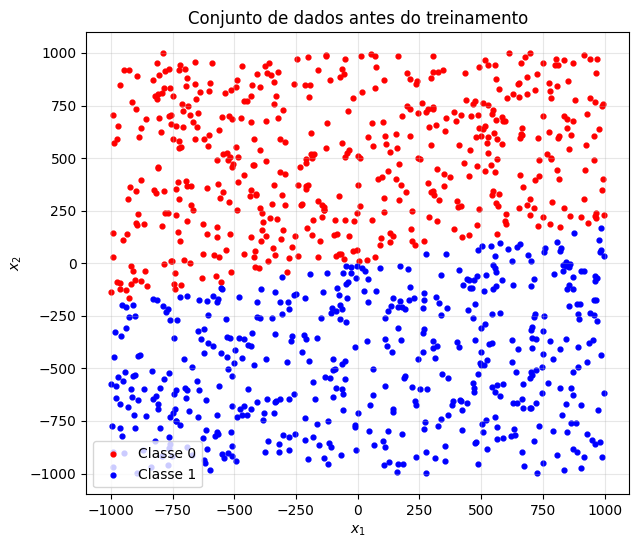

In [184]:
plt.figure(figsize=(7, 6))
plt.scatter(X_orig[y_d == 0, 0], X_orig[y_d == 0, 1], c="red",  s=12, label="Classe 0")
plt.scatter(X_orig[y_d == 1, 0], X_orig[y_d == 1, 1], c="blue", s=12, label="Classe 1")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.title("Conjunto de dados antes do treinamento")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

##Preparação da entrada: coluna de *bias* (*viés*)
O potencial de ativação é

$$u = w_0 \cdot 1 + w_1 x_1 + w_2 x_2$$

O termo $w_0$ (*bias*) equivale ao limiar e permite que a reta não passe pela origem. Acrescentar uma coluna de 1's a cada exemplo reduz o cálculo a um único produto escalar $u = \mathbf{w}\cdot\mathbf{x}$:

$$\mathbf{x} = [\,1,\; x_1,\; x_2\,] \qquad \mathbf{w} = [\,w_0,\; w_1,\; w_2\,]$$

Com isso, `X` passa a ter shape `(m, 3)`.

In [185]:
coluna_bias = np.ones((m, 1))                 # coluna de 1's, shape (m, 1)
X = np.hstack([coluna_bias, X_orig])          # junta lado a lado -> (m, 3)

print("Shape de X:", X.shape)
print("Primeiras 3 linhas de X  [1, x1, x2]:")
print(X[:3])

Shape de X: (1000, 3)
Primeiras 3 linhas de X  [1, x1, x2]:
[[   1.          547.91209711 -122.2431205 ]
 [   1.          717.19583982  394.73605812]
 [   1.         -811.64530422  951.24470327]]


## Hiperparâmetros e pesos iniciais

Exigências do enunciado:

- taxa de aprendizado $\eta = 0{,}1$;
- ativação degrau com limiar $\vartheta = 0$;
- pesos iniciais $w_i \sim U(-0{,}5, +0{,}5)$ (distribuição uniforme), **impressos no início**.


In [186]:
ETA = 0.1                 # taxa de aprendizado
Limiar = 0.0              # θ da função degrau
INTERVALO_PESOS = (-0.5, 0.5)
SEMENTE = None              # pode-se optar por um valor fixo para verificação da execução

if SEMENTE is not None:
    np.random.seed(SEMENTE)

# 3 pesos: w0 (bias), w1, w2 — sorteados uniformemente em [-0.5, 0.5)
w_inicial = np.random.uniform(INTERVALO_PESOS[0], INTERVALO_PESOS[1], size=3)

print("Vetor de pesos inicial [w0, w1, w2]:", w_inicial)

Vetor de pesos inicial [w0, w1, w2]: [ 0.3443692  -0.26511848  0.08679769]


## A teoria

**Potencial de ativação:** $u = \mathbf{w}\cdot\mathbf{x}$

**Função de ativação degrau** (com $\vartheta = 0$):

$$y = \begin{cases} 1 & \text{se } u \ge 0 \\ 0 & \text{se } u < 0 \end{cases}$$

**Regra de aprendizado do Perceptron** — só altera os pesos quando **erra**:

$$\mathbf{w} \leftarrow \mathbf{w} + \eta\,(y_d - y)\,\mathbf{x}$$

Repare no que $(y_d - y)$ faz:

| $y_d$ | $y$ (obtido) | $y_d - y$ | efeito |
|:-:|:-:|:-:|---|
| 1 | 0 | **+1** | $\mathbf{w}$ se aproxima de $\mathbf{x}$ (aumenta $u$) |
| 0 | 1 | **−1** | $\mathbf{w}$ se afasta de $\mathbf{x}$ (diminui $u$) |
| igual | igual | 0 | nada muda |

**Vocabulário:**

- **Ajuste** = cada vez que o vetor de pesos é modificado (ou seja, cada erro corrigido).
- **Época** = uma passada completa por todos os exemplos de treinamento.
- **Convergência** = uma época inteira **sem nenhum erro**.

##Implementação do Treinamento

In [187]:
def degrau(u, limiar=0.0):
    # Retorna 1 se u >= limiar, senão 0
    return 1 if u >= limiar else 0

In [188]:
def treinar_perceptron(X, y_d, eta, w_inicial, limiar=0.0,
                       max_epocas=None, max_segundos=None, embaralhar=False):
    w = w_inicial.copy()      # copia para não alterar o vetor original
    ajustes = 0               # total de vezes que w foi modificado
    epocas = 0                # épocas executadas
    convergiu = False         # vira True se uma época terminar sem erros
    historico_erros = []      # erros cometidos em cada época

    while max_epocas is None or epocas < max_epocas:      # sem limite se max_epocas=None
        epocas += 1
        # ordem de apresentação dos exemplos: aleatória (embaralhar=True) ou a original
        ordem = np.random.permutation(X.shape[0]) if embaralhar else range(X.shape[0])
        erros_na_epoca = 0

        for i in ordem:                           # percorre todos os exemplos
            u = np.dot(w, X[i])                   # (a) potencial de ativação: w · x
            y = degrau(u, limiar)                 # (b) saída do neurônio

            if y != y_d[i]:                       # errou?
                w = w + eta * (y_d[i] - y) * X[i] # (c) regra do Perceptron
                ajustes += 1
                erros_na_epoca += 1

        historico_erros.append(erros_na_epoca)

        if erros_na_epoca == 0:                   # época perfeita -> convergiu
            convergiu = True
            break

    return w, ajustes, epocas, convergiu, historico_erros

## Executando e mostrando os resultados

O enunciado pede, ao final: **(a)** número total de ajustes no vetor de pesos e **(b)** número de épocas até a convergência. (O vetor inicial já foi impresso anteriormente)

> **Convenção de contagem:** a última época (a que passa sem erros) também é contada, pois é nela que comprovamos a convergência.

In [211]:
print("Vetor de pesos inicial :", w_inicial)

w_final, total_ajustes, total_epocas, convergiu, _ = treinar_perceptron(X, y_d, ETA, w_inicial, Limiar)

tab = PrettyTable()
tab.field_names = ["Item", "Valor"]
tab.align["Item"] = "l"; tab.align["Valor"] = "l"
tab.add_row(["Vetor de pesos final [w0, w1, w2]", [round(float(v), 4) for v in w_final]])
tab.add_row(["(a) Número total de ajustes no vetor de pesos:", total_ajustes])
tab.add_row(["(b) Número de épocas até a convergência:", total_epocas])
tab.add_row(["Convergiu?", convergiu])
print(tab)

Vetor de pesos inicial : [ 0.3443692  -0.26511848  0.08679769]
+------------------------------------------------+-----------------------------+
| Item                                           | Valor                       |
+------------------------------------------------+-----------------------------+
| Vetor de pesos final [w0, w1, w2]              | [0.4444, 86.203, -425.8721] |
| (a) Número total de ajustes no vetor de pesos: | 65                          |
| (b) Número de épocas até a convergência:       | 4                           |
| Convergiu?                                     | True                        |
+------------------------------------------------+-----------------------------+


## O gráfico com os dados e a reta de separação

A fronteira de decisão é onde $u = 0$:

$$w_0 + w_1 x_1 + w_2 x_2 = 0 \;\;\Longrightarrow\;\; x_2 = -\frac{w_0 + w_1 x_1}{w_2}$$

Escolhemi dois valores de $x_1$ (as pontas do gráfico), calculei o $x_2$ correspondente e desenhei a reta entre eles. Como $x_2$ poderia sair do quadro, fixei os limites do eixo y com `plt.ylim`

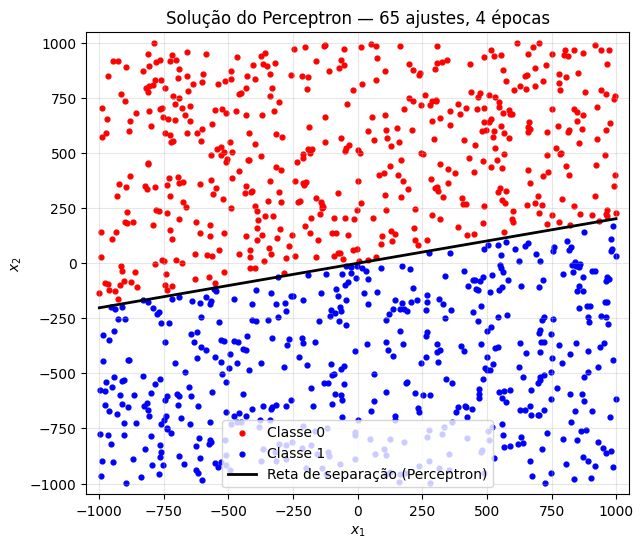

In [190]:
w0, w1, w2 = w_final

x1_reta = np.array([X_orig[:, 0].min(), X_orig[:, 0].max()])   # extremos do eixo x1
x2_reta = -(w0 + w1 * x1_reta) / w2                             # x2 correspondente

plt.figure(figsize=(7, 6))
plt.scatter(X_orig[y_d == 0, 0], X_orig[y_d == 0, 1], c="red",  s=12, label="Classe 0")
plt.scatter(X_orig[y_d == 1, 0], X_orig[y_d == 1, 1], c="blue", s=12, label="Classe 1")
plt.plot(x1_reta, x2_reta, "k-", linewidth=2, label="Reta de separação (Perceptron)")

plt.xlim(X_orig[:, 0].min() - 50, X_orig[:, 0].max() + 50)
plt.ylim(X_orig[:, 1].min() - 50, X_orig[:, 1].max() + 50)
plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.title(f"Solução do Perceptron — {total_ajustes} ajustes, {total_epocas} épocas")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Parte II – Experimentação

**Objetivo:** descobrir se a escolha da **taxa de aprendizado** ($\eta$) e do **intervalo dos pesos iniciais** ($I$) muda o desempenho do Perceptron.

O enunciado pede:

- usar o **arquivo da dupla** (`data020262.txt`);
- testar as **6 configurações** $\eta \times I = \{0{,}4;\ 0{,}1;\ 0{,}01\} \times \{(-100,+100);\ (-0{,}5,+0{,}5)\}$;
- rodar **10 repetições** de cada configuração (cada uma com pesos iniciais sorteados de novo);
- para cada configuração, registrar **média e desvio padrão do nº de ajustes**, **mínimo** e **máximo de épocas**;
- mostrar tudo numa **tabela** (`prettytable`), fazer um **boxplot** e **argumentar** se alguma configuração é melhor, pior ou se são equivalentes.

## O ID e o arquivo de dados utilizado

Regra: **somar o último dígito das matrículas** dos integrantes e aplicar o **resto da divisão por 4** (`% 4`) ao resultado. O número obtido (0, 1, 2 ou 3) é o **ID**, e ele escolhe o arquivo: ID 3 → `data320262.txt`.

Fim da matrícula é 8, resto 0 logo o arquivo utilizado será `data020262.txt`.

Exemplos: 1000 | Classe 0: 566 | Classe 1: 434


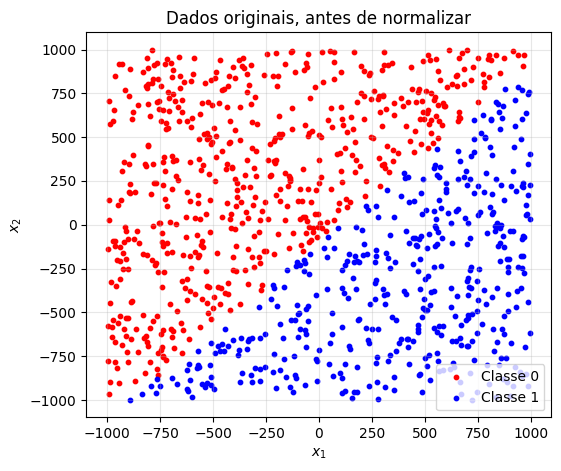

In [191]:
ID = 0
dados_exp = np.load(CAMINHO_PARTE2).reshape(-1, 3)   # (m, 3): x1, x2, yd
X_orig_exp = dados_exp[:, :2]                        # entradas (x1, x2)
y_exp      = dados_exp[:, 2]                         # saídas desejadas (0 ou 1)
m_exp      = X_orig_exp.shape[0]

print("Exemplos:", m_exp, "| Classe 0:", int(np.sum(y_exp == 0)), "| Classe 1:", int(np.sum(y_exp == 1)))

plt.figure(figsize=(6, 5))
plt.scatter(X_orig_exp[y_exp == 0, 0], X_orig_exp[y_exp == 0, 1], c="red",  s=10, label="Classe 0")
plt.scatter(X_orig_exp[y_exp == 1, 0], X_orig_exp[y_exp == 1, 1], c="blue", s=10, label="Classe 1")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.title("Dados originais, antes de normalizar")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [192]:
df_exp = pd.DataFrame(dados_exp, columns=["x1", "x2", "yd"])
df_exp["yd"] = df_exp["yd"].astype(int)

display(df_exp.head())
display(df_exp.describe().round(2))
print("Exemplos por classe:")
display(df_exp["yd"].value_counts().sort_index())

,x1,x2,yd
0,547.912097,-122.243120,1
1,717.195840,394.736058,1
2,-811.645304,951.244703,0
3,522.279404,572.128611,0
4,-743.772735,-99.228124,0


,x1,x2,yd
count,1000.00,1000.00,1000.00
mean,0.47,10.88,0.43
std,590.77,571.10,0.50
min,-998.86,-998.96,0.00
25%,-526.83,-484.87,0.00
50%,-13.78,-1.02,0.00
75%,529.40,508.70,1.00
max,998.84,998.21,1.00


Exemplos por classe:


,count
yd,
0,566
1,434


###  Normalizando as entradas

Usamos a **padronização** (*z-score*), que dá a cada coluna média 0 e desvio padrão 1:

$$x'_j = \frac{x_j - \mu_j}{\sigma_j}$$

onde $\mu_j$ e $\sigma_j$ são a média e o desvio padrão da coluna $j$ ($x_1$ ou $x_2$). Em numpy: `X.mean(axis=0)` e `X.std(axis=0)`, que calculam **uma média/desvio por coluna**.

Dois efeitos importantes:

- **Subtrair a média** centraliza os dados na origem. Isso é o que mais ajuda o bias: a fronteira de decisão passa a ficar perto da origem, onde o termo $w_0 \cdot 1$ tem peso comparável aos demais.
- **Dividir pelo desvio** deixa $x_1$ e $x_2$ na mesma faixa, e os valores deixam de ser da ordem de centenas.

A **coluna de bias (1's) é adicionada depois** de normalizar. Ela não deve ser padronizada (seu desvio é zero). Usar `Normalizar = False` volta aos dados originais, para fins de comparação.

In [193]:
NORMALIZAR = True          # True: dados padronizados | False: dados originais (para comparar)

if NORMALIZAR:
    media = X_orig_exp.mean(axis=0)                 # média de x1 e de x2
    desvio = X_orig_exp.std(axis=0)                 # desvio padrão de x1 e de x2
    desvio[desvio == 0] = 1.0                       # proteção: evita dividir por zero
    X_base = (X_orig_exp - media) / desvio          # padronização por coluna
    tab = PrettyTable()
    tab.field_names = ["", "x1", "x2"]
    tab.add_row(["Média usada"] + [f"{v:.4f}" for v in media])
    tab.add_row(["Desvio usado"] + [f"{v:.4f}" for v in desvio])
    tab.add_row(["Média após normalizar"] + [f"{v:.4f}" for v in X_base.mean(axis=0)])
    tab.add_row(["Desvio após normalizar"] + [f"{v:.4f}" for v in X_base.std(axis=0)])
    print(tab)
else:
    X_base = X_orig_exp.copy()
    print("Usando os dados ORIGINAIS (sem normalizar).")

X_exp = np.hstack([np.ones((m_exp, 1)), X_base])    # bias DEPOIS de normalizar -> (m, 3)
print("Shape de X_exp:", X_exp.shape)

+------------------------+----------+----------+
|                        |    x1    |    x2    |
+------------------------+----------+----------+
|      Média usada       |  0.4694  | 10.8775  |
|      Desvio usado      | 590.4745 | 570.8174 |
| Média após normalizar  | -0.0000  |  0.0000  |
| Desvio após normalizar |  1.0000  |  1.0000  |
+------------------------+----------+----------+
Shape de X_exp: (1000, 3)


###Sorteio dos pesos iniciais
Na Parte I sorteamos os pesos iniciais direto no corpo do notebook, sempre em $(-0{,}5, +0{,}5)$. Aqui o intervalo **varia** entre as configurações e o sorteio se repete 60 vezes, então criei uma função. Ela recebe o intervalo $I$ e devolve 3 pesos ($w_0$ bias, $w_1$, $w_2$) sorteados com distribuição uniforme.

O treinamento em si **não muda**: usamos o mesmo `treino_perceptron` da Parte I.

In [194]:
def sortear_pesos(intervalo, tamanho=3):
    # Pesos ~ Uniforme(intervalo[0], intervalo[1])
    return np.random.uniform(intervalo[0], intervalo[1], size=tamanho)

###Rodando o experimento
**Estrutura:** dois laços aninhados percorrem as 6 combinações $(\eta, I)$. Dentro deles, um terceiro laço faz as 10 repetições. Em cada repetição:

1. sorteia **novos pesos iniciais** dentro do intervalo $I$;
2. treina o Perceptron (função da Parte I);
3. guarda o **nº de ajustes** e o **nº de épocas**.


In [195]:
ETAS = [0.4, 0.1, 0.01]                          # taxas de aprendizado
INTERVALOS = [(-100, 100), (-0.5, 0.5)]          # intervalos dos pesos iniciais
N_REPETICOES = 10

np.random.seed(ID)    # uma vez só, antes dos laços (reprodutibilidade)

# resultados[(eta, intervalo)] = {"ajustes": [...10 valores...], "epocas": [...10 valores...]}
resultados = {}

for eta in ETAS:
    for intervalo in INTERVALOS:
        lista_ajustes, lista_epocas = [], []

        for rep in range(N_REPETICOES):
            w_ini = sortear_pesos(intervalo)                          # pesos novos a cada repetição
            w_fin, ajustes, epocas, convergiu, _ = treinar_perceptron(X_exp, y_exp, eta, w_ini, Limiar)

            # conferência: com os pesos finais, nenhum exemplo pode estar errado
            erros_exp = np.sum(((X_exp @ w_fin) >= Limiar).astype(int) != y_exp)
            assert convergiu and erros_exp == 0, "Convergiu mas ainda há erros?!"

            lista_ajustes.append(ajustes)
            lista_epocas.append(epocas)

        resultados[(eta, intervalo)] = {"ajustes": np.array(lista_ajustes),
                                        "epocas":  np.array(lista_epocas)}
        print(f"eta={eta:<5} I={str(intervalo):<12} concluído", flush=True)   # acompanhamento

# ajustes de cada repetição, por configuração
tab_rep = PrettyTable()
tab_rep.field_names = ["Configuração"] + [f"rep {i}" for i in range(1, N_REPETICOES + 1)]
for (eta, intervalo), r in resultados.items():
    tab_rep.add_row([f"eta={eta}, I={intervalo}"] + [int(v) for v in r["ajustes"]])
print("\nNúmero de ajustes em cada repetição")
print(tab_rep)

eta=0.4   I=(-100, 100)  concluído
eta=0.4   I=(-0.5, 0.5)  concluído
eta=0.1   I=(-100, 100)  concluído
eta=0.1   I=(-0.5, 0.5)  concluído
eta=0.01  I=(-100, 100)  concluído
eta=0.01  I=(-0.5, 0.5)  concluído

Número de ajustes em cada repetição
+-------------------------+-------+-------+-------+-------+-------+-------+-------+-------+-------+--------+
|       Configuração      | rep 1 | rep 2 | rep 3 | rep 4 | rep 5 | rep 6 | rep 7 | rep 8 | rep 9 | rep 10 |
+-------------------------+-------+-------+-------+-------+-------+-------+-------+-------+-------+--------+
|  eta=0.4, I=(-100, 100) |  114  |  275  |  578  |  353  |   94  |  1433 |  683  |  1297 |  159  |  446   |
|  eta=0.4, I=(-0.5, 0.5) |  218  |  223  |  3159 |  187  |  201  |  201  |  492  |  144  |  610  |  1681  |
|  eta=0.1, I=(-100, 100) |  1094 |  972  |  1383 |  772  |  1112 |  1094 |  963  |  1752 |  1241 |  1238  |
|  eta=0.1, I=(-0.5, 0.5) |  217  |  3197 |  264  |  1302 |  2043 |  256  |  2611 |  184  |  113  |

In [196]:
tabela = PrettyTable()
tabela.field_names = ["Taxa de Aprendizado", "Intervalo de Pesos", "Qtde Ajustes", "Min Épocas", "Max Épocas"]

for eta in ETAS:
    for intervalo in INTERVALOS:
        r = resultados[(eta, intervalo)]
        tabela.add_row([
            f"eta = {eta}",
            f"({intervalo[0]}, +{intervalo[1]})",
            f"{np.mean(r['ajustes']):.2f} ± {np.std(r['ajustes']):.2f}",
            int(np.min(r["epocas"])),
            int(np.max(r["epocas"])),
        ])

print(tabela)

+---------------------+--------------------+-------------------+------------+------------+
| Taxa de Aprendizado | Intervalo de Pesos |    Qtde Ajustes   | Min Épocas | Max Épocas |
+---------------------+--------------------+-------------------+------------+------------+
|      eta = 0.4      |    (-100, +100)    |  543.20 ± 450.76  |     5      |    170     |
|      eta = 0.4      |    (-0.5, +0.5)    |  711.60 ± 926.78  |     8      |    502     |
|      eta = 0.1      |    (-100, +100)    |  1162.10 ± 254.66 |     9      |    134     |
|      eta = 0.1      |    (-0.5, +0.5)    | 1305.00 ± 1195.94 |     5      |    521     |
|      eta = 0.01     |    (-100, +100)    | 7728.40 ± 3081.70 |     16     |    335     |
|      eta = 0.01     |    (-0.5, +0.5)    |  964.30 ± 544.29  |     12     |    273     |
+---------------------+--------------------+-------------------+------------+------------+


In [197]:
linhas_df = []
for eta in ETAS:
    for intervalo in INTERVALOS:
        r = resultados[(eta, intervalo)]
        linhas_df.append({"eta": eta,
                          "intervalo": str(intervalo),
                          "ajustes (média)": np.mean(r["ajustes"]),
                          "ajustes (desvio)": np.std(r["ajustes"]),
                          "min épocas": int(np.min(r["epocas"])),
                          "max épocas": int(np.max(r["epocas"]))})

df_resultados = pd.DataFrame(linhas_df)
display(df_resultados.round(2))

,eta,intervalo,ajustes (média),ajustes (desvio),min épocas,max épocas
0,0.40,"(-100, 100)",543.2,450.76,5,170
1,0.40,"(-0.5, 0.5)",711.6,926.78,8,502
2,0.10,"(-100, 100)",1162.1,254.66,9,134
3,0.10,"(-0.5, 0.5)",1305.0,1195.94,5,521
4,0.01,"(-100, 100)",7728.4,3081.70,16,335
5,0.01,"(-0.5, 0.5)",964.3,544.29,12,273


### Boxplot dos experimentos

Dois painéis com as mesmas 6 configurações: **nº de ajustes** e **nº de épocas**. A caixa mostra os quartis, a linha interna é a mediana e os pontos isolados são valores atípicos.

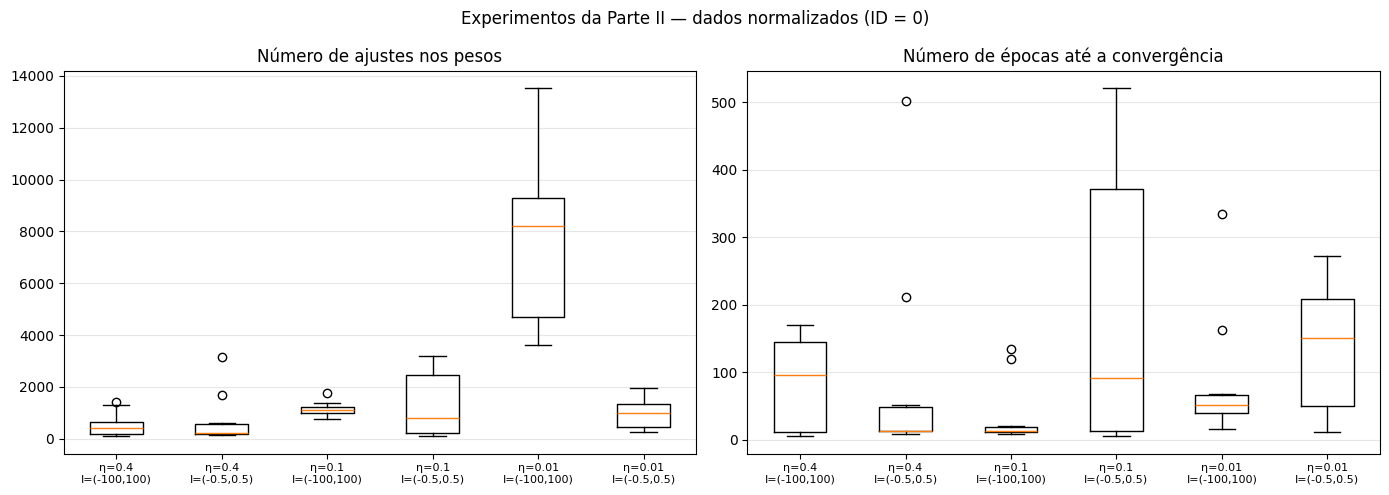

In [198]:
rotulos, dados_ajustes, dados_epocas = [], [], []
for eta in ETAS:
    for intervalo in INTERVALOS:
        rotulos.append(f"η={eta}\nI=({intervalo[0]},{intervalo[1]})")
        dados_ajustes.append(resultados[(eta, intervalo)]["ajustes"])
        dados_epocas.append(resultados[(eta, intervalo)]["epocas"])

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
for ax, dados_box, titulo in [(eixos[0], dados_ajustes, "Número de ajustes nos pesos"),
                              (eixos[1], dados_epocas,  "Número de épocas até a convergência")]:
    ax.boxplot(dados_box)
    ax.set_xticklabels(rotulos, fontsize=8)
    ax.set_title(titulo); ax.grid(axis="y", alpha=0.3)

plt.suptitle(f"Experimentos da Parte II — {'dados normalizados' if NORMALIZAR else 'dados originais'} (ID = 0)")
plt.tight_layout(); plt.show()

### Análise dos resultados

O ranking abaixo organiza as configurações pela média de ajustes e pelo coeficiente de variação (desvio ÷ média).

In [199]:
linhas = []
for eta in ETAS:
    for intervalo in INTERVALOS:
        aj = resultados[(eta, intervalo)]["ajustes"]
        linhas.append((np.mean(aj), np.std(aj), eta, intervalo))
linhas.sort(key=lambda t: t[0])

ranking = PrettyTable()
ranking.field_names = ["Posição", "Configuração", "Média de ajustes", "Desvio", "Coef. de variação"]
for pos, (media_aj, desvio_aj, eta, intervalo) in enumerate(linhas, start=1):
    cv = desvio_aj / media_aj if media_aj > 0 else 0
    ranking.add_row([pos, f"eta={eta}, I={intervalo}", f"{media_aj:.1f}", f"{desvio_aj:.1f}", f"{cv:.2f}"])
print(ranking)

melhor, pior = linhas[0], linhas[-1]
print(f"\nMenor média de ajustes: eta={melhor[2]}, I={melhor[3]} ({melhor[0]:.1f})")
print(f"Maior média de ajustes: eta={pior[2]}, I={pior[3]} ({pior[0]:.1f})")
print(f"A pior média é {pior[0] / melhor[0]:.1f}x a melhor.")

+---------+-------------------------+------------------+--------+-------------------+
| Posição |       Configuração      | Média de ajustes | Desvio | Coef. de variação |
+---------+-------------------------+------------------+--------+-------------------+
|    1    |  eta=0.4, I=(-100, 100) |      543.2       | 450.8  |        0.83       |
|    2    |  eta=0.4, I=(-0.5, 0.5) |      711.6       | 926.8  |        1.30       |
|    3    | eta=0.01, I=(-0.5, 0.5) |      964.3       | 544.3  |        0.56       |
|    4    |  eta=0.1, I=(-100, 100) |      1162.1      | 254.7  |        0.22       |
|    5    |  eta=0.1, I=(-0.5, 0.5) |      1305.0      | 1195.9 |        0.92       |
|    6    | eta=0.01, I=(-100, 100) |      7728.4      | 3081.7 |        0.40       |
+---------+-------------------------+------------------+--------+-------------------+

Menor média de ajustes: eta=0.4, I=(-100, 100) (543.2)
Maior média de ajustes: eta=0.01, I=(-100, 100) (7728.4)
A pior média é 14.2x a melh

#### Análise e argumentação

**Pré-processamento.**

**Resultados.**

**Existe uma configuração melhor ou pior?**

**Influência de $\eta$ e de $I$.**

**Variabilidade.**

**Conclusão.**

---
# PARTE III – Validação *Holdout* em um problema não linearmente separável

**Objetivo:** treinar o Perceptron em um problema onde **nenhuma reta separa as classes** e avaliar quão bem a solução obtida **generaliza**, ou seja, quão bem ela acerta exemplos que **não** foram usados no treinamento.

**O que muda em relação às Partes I e II**

| | Partes I e II | Parte III |
|---|---|---|
| Dados | linearmente separáveis (em tese) | **não** linearmente separáveis |
| Critério de parada | até **convergir** (zero erros) | **100 épocas fixas** (nunca zera os erros) |
| Ordem dos exemplos | sempre a mesma | **embaralhada a cada época** |
| Dados usados | todos no treino | **70% treino / 30% teste** |
| Avaliação | nº de ajustes e épocas | **matriz de confusão, acurácia, precisão, revocação e F-score** |


Exemplos: 1000
Classe 0: 492 | Classe 1: 508


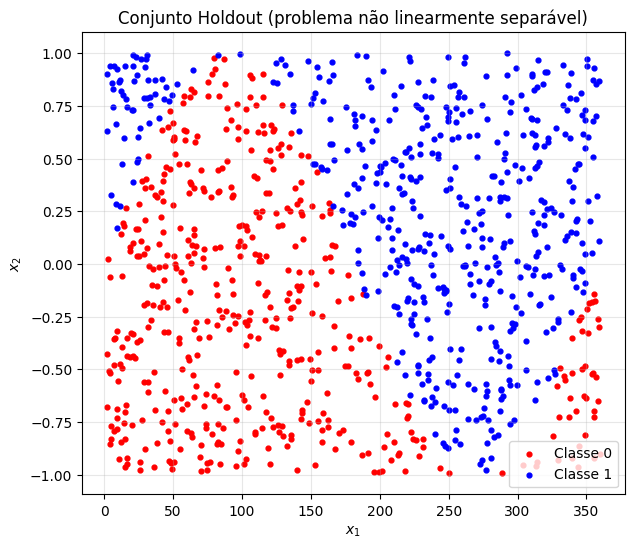

In [200]:
dados_h = np.load(CAMINHO_PARTE3).reshape(-1, 3)   # (m, 3): x1, x2, yd

X_orig_h = dados_h[:, :2]                          # entradas (x1, x2)
y_h      = dados_h[:, 2].astype(int)               # rótulos (0 ou 1) como inteiros
m_h      = X_orig_h.shape[0]

print("Exemplos:", m_h)
print("Classe 0:", int(np.sum(y_h == 0)), "| Classe 1:", int(np.sum(y_h == 1)))

plt.figure(figsize=(7, 6))
plt.scatter(X_orig_h[y_h == 0, 0], X_orig_h[y_h == 0, 1], c="red",  s=12, label="Classe 0")
plt.scatter(X_orig_h[y_h == 1, 0], X_orig_h[y_h == 1, 1], c="blue", s=12, label="Classe 1")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.title("Conjunto Holdout (problema não linearmente separável)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Divisão em treino (70%) e teste (30%)

Avaliar o neurônio nos mesmos exemplos do treino produziria um resultado otimista. O conjunto de teste reúne exemplos nunca vistos e mede a capacidade de generalização (validação *holdout*).

A divisão é feita sem `train_test_split`, que não é permitido:

1. `np.random.seed(ID)` fixa a divisão, como pede o enunciado;
2. `np.random.permutation(m)` embaralha os índices;
3. os primeiros 70% vão para o treino e os 30% restantes para o teste.

Embaralhar antes de cortar evita que um arquivo ordenado deixe apenas uma classe no teste.

In [201]:
np.random.seed(ID)                         # semente = identificador da equipe

indices = np.random.permutation(m_h)       # índices embaralhados
n_treino = int(0.7 * m_h)                  # 70% para treino

idx_treino = indices[:n_treino]
idx_teste  = indices[n_treino:]

# Conferência para garantir que nenhum exemplo pode esteja duas partições
assert len(np.intersect1d(idx_treino, idx_teste)) == 0
assert len(idx_treino) + len(idx_teste) == m_h

# Monta as matrizes (com a coluna de bias à esquerda, como nas partes anteriores)
X_tr = np.hstack([np.ones((len(idx_treino), 1)), X_orig_h[idx_treino]])
y_tr = y_h[idx_treino]
X_te = np.hstack([np.ones((len(idx_teste), 1)), X_orig_h[idx_teste]])
y_te = y_h[idx_teste]

tab = PrettyTable()
tab.field_names = ["Conjunto", "Exemplos", "Classe 0", "Classe 1"]
tab.add_row(["Treino", len(y_tr), int(np.sum(y_tr == 0)), int(np.sum(y_tr == 1))])
tab.add_row(["Teste", len(y_te), int(np.sum(y_te == 0)), int(np.sum(y_te == 1))])
print(tab)

+----------+----------+----------+----------+
| Conjunto | Exemplos | Classe 0 | Classe 1 |
+----------+----------+----------+----------+
|  Treino  |   700    |   354    |   346    |
|  Teste   |   300    |   138    |   162    |
+----------+----------+----------+----------+


In [202]:
ETA_H = 0.1
N_EPOCAS = 100
LIMIAR_H = 0.0

w_ini_h = np.random.uniform(-0.5, 0.5, size=3)           # pesos ~ U(-0.5, +0.5)
print("Pesos iniciais [w0, w1, w2]:", w_ini_h)

# mesma função da Parte I: 100 épocas fixas e exemplos embaralhados a cada época
w_h, ajustes_h, epocas_h, _, hist_erros = treinar_perceptron(
    X_tr, y_tr, ETA_H, w_ini_h, LIMIAR_H,
    max_epocas=N_EPOCAS, embaralhar=True)

tab = PrettyTable()
tab.field_names = ["Item", "Valor"]
tab.align["Item"] = "l"; tab.align["Valor"] = "l"
tab.add_row(["Pesos finais [w0, w1, w2]", [round(float(v), 4) for v in w_h]])
tab.add_row(["Épocas executadas", epocas_h])
tab.add_row(["Total de ajustes", ajustes_h])
tab.add_row(["Erros na última época", f"{hist_erros[-1]} de {len(y_tr)} exemplos de treino"])
print(tab)

Pesos iniciais [w0, w1, w2]: [ 0.49207384 -0.1447748   0.34834015]
+---------------------------+-------------------------------+
| Item                      | Valor                         |
+---------------------------+-------------------------------+
| Pesos finais [w0, w1, w2] | [-645.8079, 1.3845, 594.1275] |
| Épocas executadas         | 100                           |
| Total de ajustes          | 29951                         |
| Erros na última época     | 255 de 700 exemplos de treino |
+---------------------------+-------------------------------+


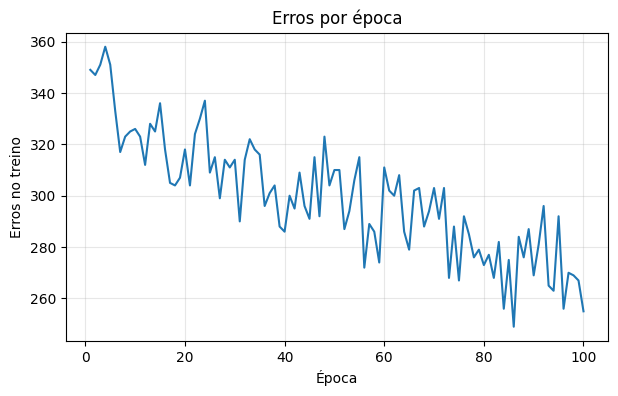

In [203]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(hist_erros) + 1), hist_erros)
plt.xlabel("Época"); plt.ylabel("Erros no treino")
plt.title("Erros por época")
plt.grid(alpha=0.3)
plt.show()

## Previsões no teste e matriz de confusão

As saídas de todos os exemplos de teste são calculadas de uma vez: `X_te @ w` dá o potencial $u$ e `>= limiar` aplica o degrau. A matriz de confusão compara o rótulo real com o previsto, com a classe 1 como positiva:

|  | previsto 0 | previsto 1 |
|---|:-:|:-:|
| **real 0** | VN | FP |
| **real 1** | FN | VP |

VN e VP são os acertos; FP são exemplos da classe 0 classificados como 1; FN são exemplos da classe 1 classificados como 0. A matriz é calculada com numpy e conferida com `sklearn.metrics.confusion_matrix`.

In [204]:
def prever(X, w, limiar=0.0):
    return (X @ w >= limiar).astype(int)          # degrau aplicado a todos os exemplos

def matriz_confusao(y_real, y_pred):
    vn = np.sum((y_real == 0) & (y_pred == 0))
    fp = np.sum((y_real == 0) & (y_pred == 1))
    fn = np.sum((y_real == 1) & (y_pred == 0))
    vp = np.sum((y_real == 1) & (y_pred == 1))
    return np.array([[vn, fp],
                     [fn, vp]])

y_pred_tr = prever(X_tr, w_h, LIMIAR_H)
y_pred_te = prever(X_te, w_h, LIMIAR_H)

mc_te = matriz_confusao(y_te, y_pred_te)

# conferência com o sklearn (precisa ser exatamente igual)
assert np.array_equal(mc_te, confusion_matrix(y_te, y_pred_te, labels=[0, 1]))

tab_mc = PrettyTable()
tab_mc.field_names = ["", "previsto 0", "previsto 1"]
tab_mc.add_row(["real 0", f"VN = {mc_te[0,0]}", f"FP = {mc_te[0,1]}"])
tab_mc.add_row(["real 1", f"FN = {mc_te[1,0]}", f"VP = {mc_te[1,1]}"])
print("MATRIZ DE CONFUSÃO — conjunto de TESTE")
print(tab_mc)

MATRIZ DE CONFUSÃO — conjunto de TESTE
+--------+------------+------------+
|        | previsto 0 | previsto 1 |
+--------+------------+------------+
| real 0 |  VN = 137  |   FP = 1   |
| real 1 |  FN = 110  |  VP = 52   |
+--------+------------+------------+


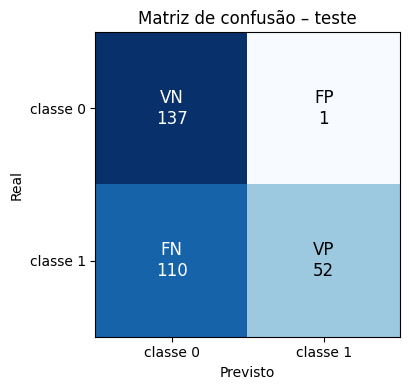

In [205]:
def plotar_matriz_confusao(mc, titulo):
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.imshow(mc, cmap="Blues")

    rotulos = ["classe 0", "classe 1"]
    ax.set_xticks([0, 1]); ax.set_xticklabels(rotulos)
    ax.set_yticks([0, 1]); ax.set_yticklabels(rotulos)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
    ax.set_title(titulo)

    nomes = [["VN", "FP"], ["FN", "VP"]]
    limite = mc.max() / 2
    for i in range(2):
        for j in range(2):
            cor = "white" if mc[i, j] > limite else "black"   # texto legível sobre o fundo
            ax.text(j, i, f"{nomes[i][j]}\n{mc[i, j]}",
                    ha="center", va="center", color=cor, fontsize=12)

    plt.tight_layout()
    plt.show()

plotar_matriz_confusao(mc_te, "Matriz de confusão – teste")

## Acurácia

$$\text{acurácia} = \frac{VP + VN}{VP + VN + FP + FN}$$

Fração de exemplos classificados corretamente. A questão 2 do enunciado menciona a acurácia "para os dados do conjunto de treinamento", o que é ambíguo; por isso são calculadas as acuráceas de treino e de teste. Uma diferença grande entre as duas indica má generalização.

Também é calculada uma linha de base (*baseline*): a acurácia de um classificador que sempre responde a classe mais frequente do treino. Serve de referência mínima para a solução.

In [206]:
def acuracia(y_real, y_pred):
    return np.mean(y_real == y_pred)              # fração de acertos

acc_tr = acuracia(y_tr, y_pred_tr)
acc_te = acuracia(y_te, y_pred_te)

# conferência com o sklearn
assert np.isclose(acc_tr, accuracy_score(y_tr, y_pred_tr))
assert np.isclose(acc_te, accuracy_score(y_te, y_pred_te))

# linha de base: sempre prever a classe mais frequente do treino
classe_majoritaria = int(np.sum(y_tr == 1) > np.sum(y_tr == 0))
baseline_te = np.mean(y_te == classe_majoritaria)

tab_acc = PrettyTable()
tab_acc.field_names = ["Item", "Acurácia"]
tab_acc.align["Item"] = "l"
tab_acc.add_row(["Treino", f"{acc_tr*100:.2f}%"])
tab_acc.add_row(["Teste", f"{acc_te*100:.2f}%"])
tab_acc.add_row([f"Linha de base no teste (sempre prever a classe {classe_majoritaria})", f"{baseline_te*100:.2f}%"])
print(tab_acc)

+---------------------------------------------------+----------+
| Item                                              | Acurácia |
+---------------------------------------------------+----------+
| Treino                                            |  63.29%  |
| Teste                                             |  63.00%  |
| Linha de base no teste (sempre prever a classe 0) |  46.00%  |
+---------------------------------------------------+----------+


## Precisão, revocação e F-score

Métricas da classe positiva (classe 1), úteis quando a acurácia sozinha pode enganar:

$$\text{precisão} = \frac{VP}{VP + FP} \qquad \text{revocação} = \frac{VP}{VP + FN} \qquad F = \frac{2 \cdot \text{precisão} \cdot \text{revocação}}{\text{precisão} + \text{revocação}}$$

- **Precisão:** fração dos exemplos classificados como 1 que realmente são 1 (penaliza falsos positivos).
- **Revocação:** fração dos exemplos realmente 1 que foram encontrados (penaliza falsos negativos).
- **F-score:** média harmônica das duas; só é alta quando ambas são altas.

Calculadas a partir da matriz de confusão e conferidas com `sklearn.metrics`, para treino e teste.

In [207]:
def metricas(y_real, y_pred):
    mc = matriz_confusao(y_real, y_pred)
    vn, fp, fn, vp = [int(v) for v in mc.ravel()]
    precisao  = vp / (vp + fp) if (vp + fp) > 0 else 0.0     # evita divisão por zero
    revocacao = vp / (vp + fn) if (vp + fn) > 0 else 0.0
    f_score = 2 * precisao * revocacao / (precisao + revocacao) if (precisao + revocacao) > 0 else 0.0
    return precisao, revocacao, f_score

p_tr, r_tr, f_tr = metricas(y_tr, y_pred_tr)
p_te, r_te, f_te = metricas(y_te, y_pred_te)

# conferência com o sklearn
assert np.isclose(p_te, precision_score(y_te, y_pred_te, zero_division=0))
assert np.isclose(r_te, recall_score(y_te, y_pred_te, zero_division=0))
assert np.isclose(f_te, f1_score(y_te, y_pred_te, zero_division=0))

tabela_metricas = PrettyTable()
tabela_metricas.field_names = ["Métrica", "Treino", "Teste"]
tabela_metricas.add_row(["Acurácia",  f"{acc_tr:.4f}", f"{acc_te:.4f}"])
tabela_metricas.add_row(["Precisão",  f"{p_tr:.4f}",   f"{p_te:.4f}"])
tabela_metricas.add_row(["Revocação", f"{r_tr:.4f}",   f"{r_te:.4f}"])
tabela_metricas.add_row(["F-score",   f"{f_tr:.4f}",   f"{f_te:.4f}"])
print(tabela_metricas)

+-----------+--------+--------+
|  Métrica  | Treino | Teste  |
+-----------+--------+--------+
|  Acurácia | 0.6329 | 0.6300 |
|  Precisão | 0.9495 | 0.9811 |
| Revocação | 0.2717 | 0.3210 |
|  F-score  | 0.4225 | 0.4837 |
+-----------+--------+--------+


## Discussão da qualidade da solução

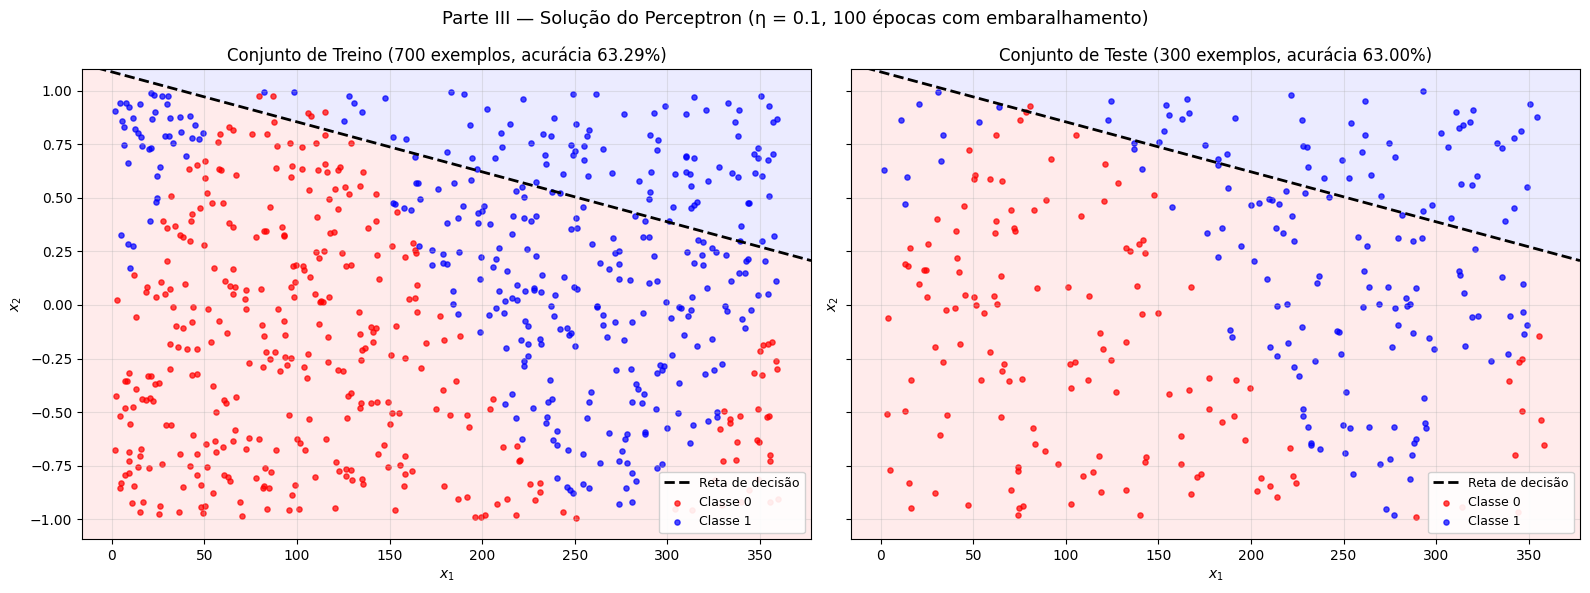

In [208]:
def plotar_com_reta(ax, X_orig, y, w, titulo, lim_x, lim_y):
    w0, w1, w2 = w
    xs = np.linspace(lim_x[0], lim_x[1], 400)

    # regiões de decisão: classe 1 onde u >= 0 (azul claro), classe 0 onde u < 0 (vermelho claro)
    if abs(w2) > 1e-12:
        x2_reta = -(w0 + w1 * xs) / w2                          # fronteira: x2 em função de x1
        linha = np.clip(x2_reta, lim_y[0], lim_y[1])            # mantém o preenchimento dentro do quadro
        topo, base = lim_y[1], lim_y[0]
        if w2 > 0:      # classe 1 acima da reta
            ax.fill_between(xs, linha, topo, color="blue", alpha=0.08, linewidth=0)
            ax.fill_between(xs, base, linha, color="red",  alpha=0.08, linewidth=0)
        else:           # classe 1 abaixo da reta
            ax.fill_between(xs, base, linha, color="blue", alpha=0.08, linewidth=0)
            ax.fill_between(xs, linha, topo, color="red",  alpha=0.08, linewidth=0)
        ax.plot(xs, x2_reta, "k--", linewidth=2, label="Reta de decisão")
    else:
        x_v = -w0 / w1                                          # reta vertical
        esq, dir_ = (lim_x[0], x_v), (x_v, lim_x[1])
        ax.axvspan(*esq, color=("red" if w1 > 0 else "blue"), alpha=0.08, linewidth=0)
        ax.axvspan(*dir_, color=("blue" if w1 > 0 else "red"), alpha=0.08, linewidth=0)
        ax.axvline(x_v, color="k", linestyle="--", linewidth=2, label="Reta de decisão")

    ax.scatter(X_orig[y == 0, 0], X_orig[y == 0, 1], c="red",  s=14, alpha=0.7, label="Classe 0")
    ax.scatter(X_orig[y == 1, 0], X_orig[y == 1, 1], c="blue", s=14, alpha=0.7, label="Classe 1")

    ax.set_xlim(lim_x); ax.set_ylim(lim_y)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right", fontsize=9, framealpha=0.9)


# limites com 5% de folga em volta dos dados (funciona com dados originais ou normalizados)
def limites(v):
    folga = 0.05 * (v.max() - v.min())
    return (v.min() - folga, v.max() + folga)

lim_x = limites(X_orig_h[:, 0])
lim_y = limites(X_orig_h[:, 1])

fig, (ax_tr, ax_te) = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

plotar_com_reta(ax_tr, X_tr[:, 1:], y_tr, w_h,
                f"Conjunto de Treino ({len(y_tr)} exemplos, acurácia {acc_tr*100:.2f}%)", lim_x, lim_y)
plotar_com_reta(ax_te, X_te[:, 1:], y_te, w_h,
                f"Conjunto de Teste ({len(y_te)} exemplos, acurácia {acc_te*100:.2f}%)", lim_x, lim_y)

plt.suptitle(f"Parte III — Solução do Perceptron (η = {ETA_H}, {N_EPOCAS} épocas com embaralhamento)", fontsize=13)
plt.tight_layout()
plt.show()